<a href="https://colab.research.google.com/github/renoegneo/MLclasswork/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22Untitled0_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os

print(os.listdir("/content"))


['.config', 'ML_Modul1_datasets.zip', 'sample_data']


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'ML_Modul1_datasets.zip', 'sample_data']


In [ ]:

import os
print(os.listdir("/content"))


['.config', 'ML_Modul1_datasets.zip', 'sample_data']


In [ ]:

import zipfile
import os

zip_path = "/content/ML_Modul1_datasets.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/datasets")

print("Архив распакован!")
print(os.listdir("/content/datasets"))


Архив распакован!
['README.txt', 'healthcare-dataset-stroke-data.csv', 'adult.csv', 'hotel_bookings.csv', 'bank-additional-full.csv']


In [ ]:

import os

for root, dirs, files in os.walk("/content/datasets"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


/content/datasets/healthcare-dataset-stroke-data.csv
/content/datasets/adult.csv
/content/datasets/hotel_bookings.csv
/content/datasets/bank-additional-full.csv


In [ ]:

import os
import pandas as pd

csv_path = None

for root, dirs, files in os.walk("/content/datasets"):
    for file in files:
        if file == "bank-additional-full.csv":
            csv_path = os.path.join(root, file)
            break
    if csv_path:
        break

if csv_path is None:
    print("Файл bank-additional-full.csv не найден.")
else:
    df = pd.read_csv(csv_path, sep=";")
    print("Данные загружены успешно!")
    print("Размер датасета:", df.shape)
    display(df.head())


Данные загружены успешно!
Размер датасета: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:

import pandas as pd

df = pd.read_csv(
    "/content/datasets/bank-additional-full.csv",
    sep=";"
)

print("Размер датасета:", df.shape)
display(df.head())


Размер датасета: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = df.dropna(subset=["y"]).copy()

X = df.drop(columns=["y"])
y = df["y"].map({"no": 0, "yes": 1})

cat_cols = X.select_dtypes(include=["object", "category"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

print("Категориальных признаков:", len(cat_cols))
print("Числовых признаков:", len(num_cols))
print("Данные готовы!")



Категориальных признаков: 10
Числовых признаков: 10
Данные готовы!


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Модель обучена успешно!")


Модель обучена успешно!


In [ ]:

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")


Accuracy: 0.8651
Accuracy: 86.51%


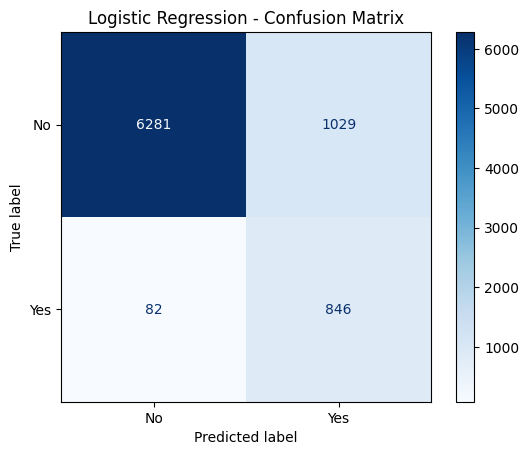

Матрица ошибок:
[[6281 1029]
 [  82  846]]


In [ ]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print("Матрица ошибок:")
print(cm)
